<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates Lab**


Estimated time needed: **30** minutes


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


In [1]:
!pip install pandas
!pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.5 MB 6.4 MB/s eta 0:00:01
   ---------------- ----------------------- 1.0/2.5 MB 2.2 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.5 MB 2.4 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.5 MB 2.0 MB/s eta 0:00:01
   --------------------------------- ------ 2.1/2.5 MB 1.9 MB/s eta 0:00:01
   --------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Import pandas module


In [2]:
import pandas as pd


Import matplotlib


In [3]:
import matplotlib.pyplot as plt


## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


In [4]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)
#pd.read_csv() legge il file CSV e lo converte in un DataFrame Pandas, cioè una struttura tabellare composta da righe e colonne.
#Nel dataset:
#-ogni riga rappresenta una risposta al sondaggio;
#-ogni colonna rappresenta una domanda o un attributo;
#-ResponseId identifica la risposta;
#-il dataset contiene 114 colonne.

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [5]:
#df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")


## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [5]:
## Write your code here
duplicate_count = df.duplicated().sum()
#Con df.duplicated() Per ogni riga, Pandas verifica se esiste una riga precedente con esattamente gli stessi valori in tutte le colonne.
#Il risultato è una serie di valori booleani:

#con .sum() calcola il numero totale di valori True nella serie, che corrisponde al numero di righe duplicate nel DataFrame.
#abbiamo controllato i duplicati completi Perché una riga completamente duplicata può alterare l’analisi. Per esempio, può:
#-aumentare artificialmente il numero di rispondenti;
#-modificare le percentuali;
#-influenzare le distribuzioni;
#-dare più peso a una determinata risposta.

duplicate_rows=df[df.duplicated()]
# Visualizziamo le righe duplicate
# lo facciamo perchè Contare i duplicati non è sufficiente. È importante anche visualizzarli per capire:
#-quali risposte sono duplicate;
#-se sono veramente identiche;
#-se il problema riguarda poche righe o molti record;
#-se potrebbe trattarsi di un errore nella raccolta dati.

print("Number of duplicate rows:", duplicate_count)
print(duplicate_rows.head())


Number of duplicate rows: 20
       ResponseId                      MainBranch                 Age  \
65437           1  I am a developer by profession  Under 18 years old   
65438           2  I am a developer by profession     35-44 years old   
65439           3  I am a developer by profession     45-54 years old   
65440           4           I am learning to code     18-24 years old   
65441           5  I am a developer by profession     18-24 years old   

                Employment RemoteWork   Check  \
65437  Employed, full-time     Remote  Apples   
65438  Employed, full-time     Remote  Apples   
65439  Employed, full-time     Remote  Apples   
65440   Student, full-time        NaN  Apples   
65441   Student, full-time        NaN  Apples   

                                        CodingActivities  \
65437                                              Hobby   
65438  Hobby;Contribute to open-source projects;Other...   
65439  Hobby;Contribute to open-source projects;Other... 

### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   


In [6]:
## Write your code here
pattern_columns=["MainBranch","Employment","RemoteWork"]
# Conta quante risposte appartengono a ciascun pattern
response_patterns=(df.groupby(pattern_columns, dropna=False).size().reset_index(name="ResponseCount").sort_values("ResponseCount", ascending=False))
#df.groupby(pattern_columns, dropna=False) raggruppa il DataFrame in base ai valori delle colonne specificate in pattern_columns. Ogni gruppo rappresenta un pattern unico di risposte.
#dropna=False indica che i valori NaN (mancanti) devono essere considerati come un valore valido durante il raggruppamento.
#.size() calcola la dimensione di ciascun gruppo, cioè il numero di risposte che condividono lo stesso pattern.
#.reset_index(name="ResponseCount") trasforma l'oggetto GroupBy in un DataFrame, con una nuova colonna chiamata "ResponseCount" che contiene il conteggio delle risposte per ciascun pattern.
#.sort_values("ResponseCount", ascending=False) ordina il DataFrame risultante in base alla colonna "ResponseCount"

#mostra i pattern presenti più di una volta
response_patterns_multiple=response_patterns[response_patterns['ResponseCount']>1]
print(response_patterns_multiple.head(10))
print("-"*100)

#crea chiave per identificare ogni pattern
df['PatternID']=( df[pattern_columns].fillna("Missing").astype(str).agg(" | ".join, axis=1))


#*****************************************************************
#conta le occorrenze di ogni pattern
pattern_count=df["PatternID"].value_counts()

#seleziona i pattern condivisi da almeno due intervistati
repeated_patterns=pattern_count[pattern_count>1].index

#visualizza le risposte appartenenti ai pattern ripetuti
pattern_rows=df[df["PatternID"].isin(repeated_patterns)]

print(pattern_rows.head())
print("-"*100)

#colonne da analizzare escluse quelle usate per creare il pattern
other_columns=[column for column in df.columns if column not in pattern_columns + ["PatternID"]]

#calcola per ogni gruppo quante risposte hanno lo stesso valore
identical_values_by_column={}

for column in other_columns:
    matching_group=0

    for _,group in pattern_rows.groupby("PatternID" , dropna=False):
        # Un gruppo con almeno due rispondenti condivide il valore
        # se il numero di valori distinti è al massimo uno        
        if group[column].nunique(dropna=False)==1:
            matching_group+=1

    identical_values_by_column[column]=matching_group
    
#ordina le colonne per frequenza di valori identici
identical_values_summary=( pd.Series(identical_values_by_column, name="MatchingPatternGroups").sort_values(ascending=False))

print(identical_values_summary.head(15))
print("-"*100)

#Interpretazione:
#MainBranch, Employment e RemoteWork definiscono il pattern iniziale;
#ogni gruppo può contenere più rispondenti distinti;
#le colonne con il maggior numero di MatchingPatternGroups sono quelle che più frequentemente presentano lo stesso valore all’interno dei gruppi;
#ciò indica una somiglianza nelle risposte, non necessariamente la presenza di record duplicati.

                                            MainBranch  \
0                       I am a developer by profession   
2                       I am a developer by profession   
1                       I am a developer by profession   
82                      I am a developer by profession   
9                       I am a developer by profession   
244                              I am learning to code   
280  I am not primarily a developer, but I write co...   
111                     I am a developer by profession   
456                        I code primarily as a hobby   
7                       I am a developer by profession   

                                            Employment  \
0                                  Employed, full-time   
2                                  Employed, full-time   
1                                  Employed, full-time   
82   Independent contractor, freelancer, or self-em...   
9    Employed, full-time;Independent contractor, fr...   
244          

### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


C:\Users\fabrizio_beggiato\AppData\Local\Temp\ipykernel_35156\684167670.py:39: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


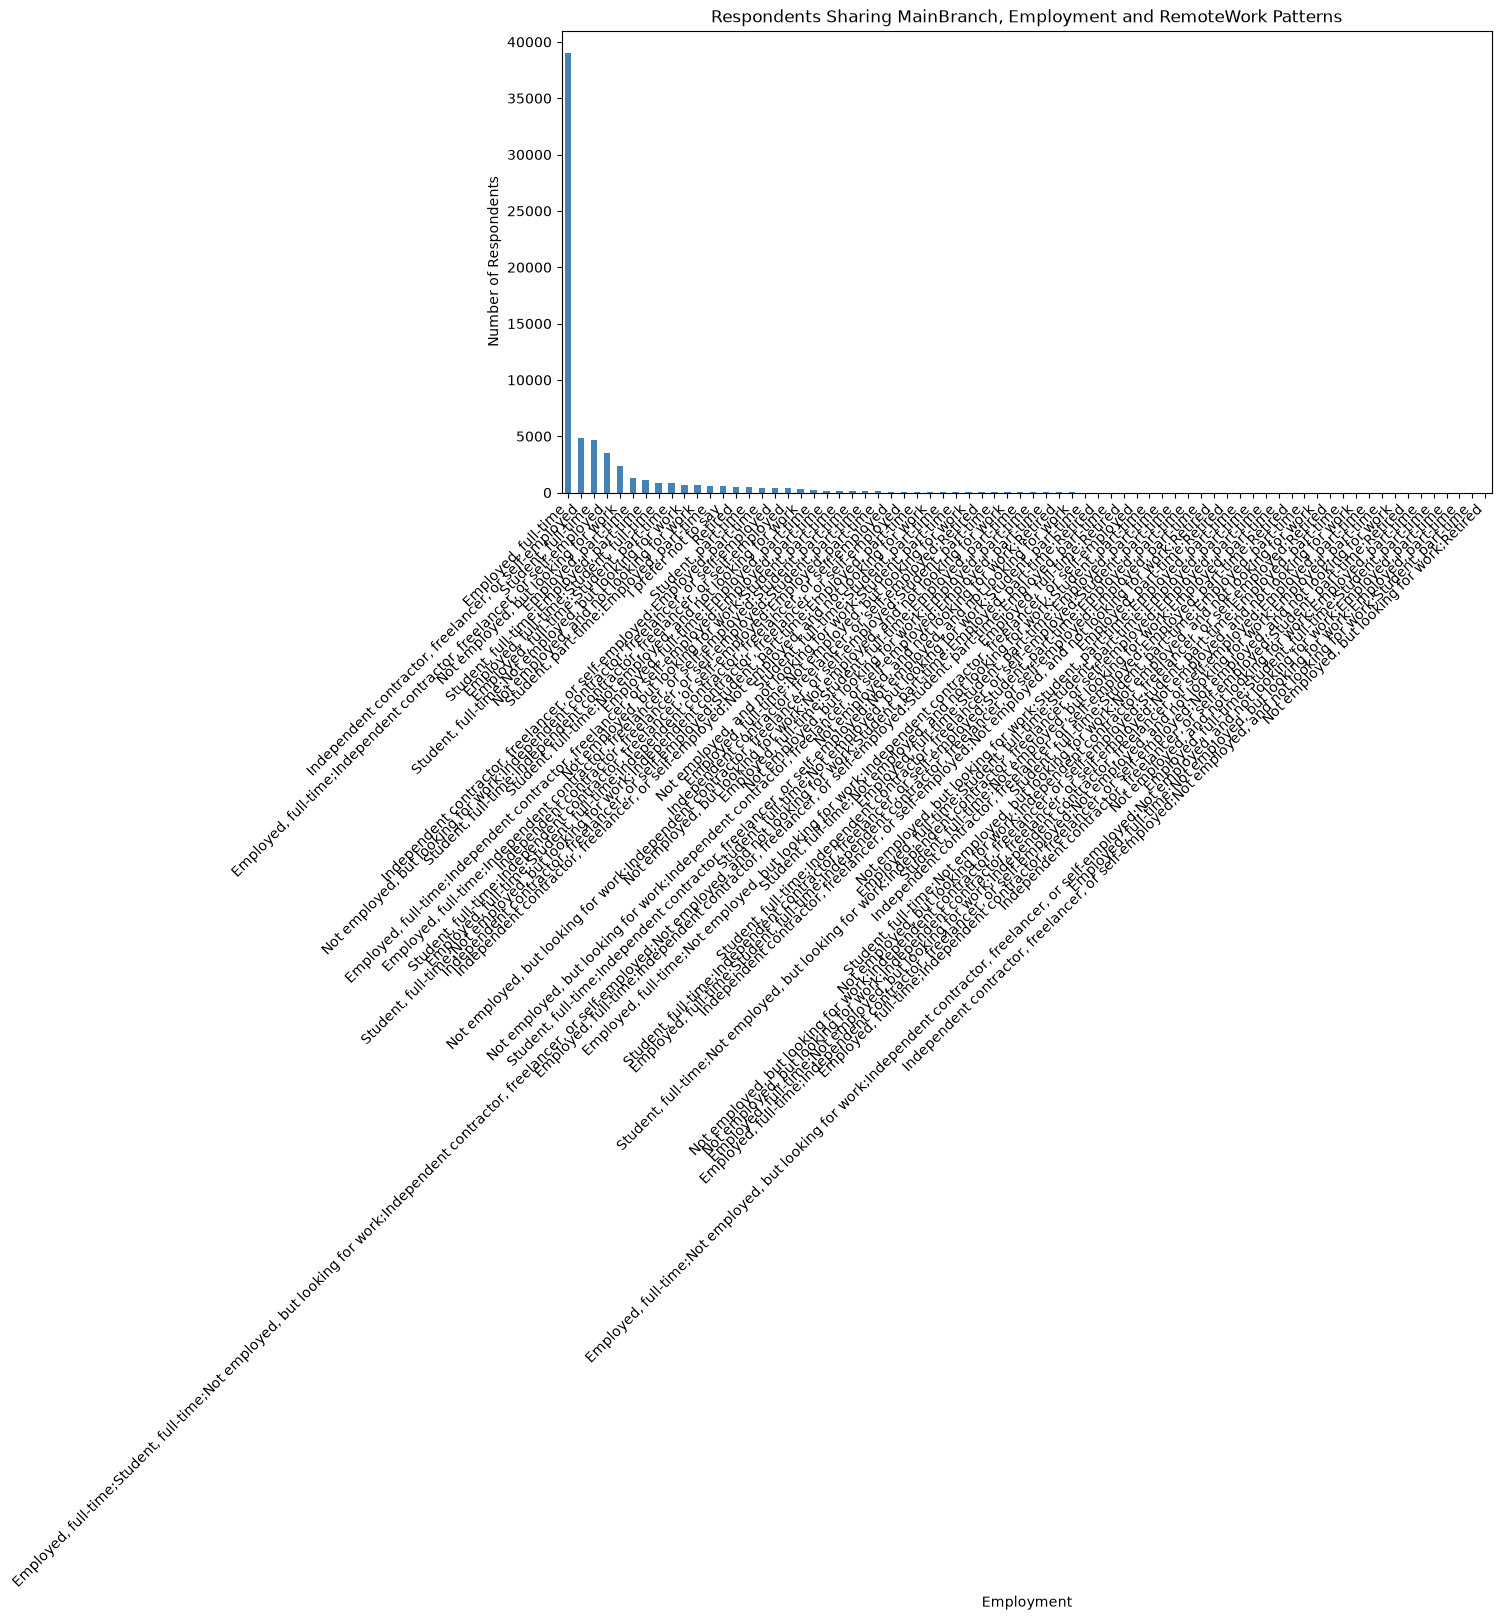

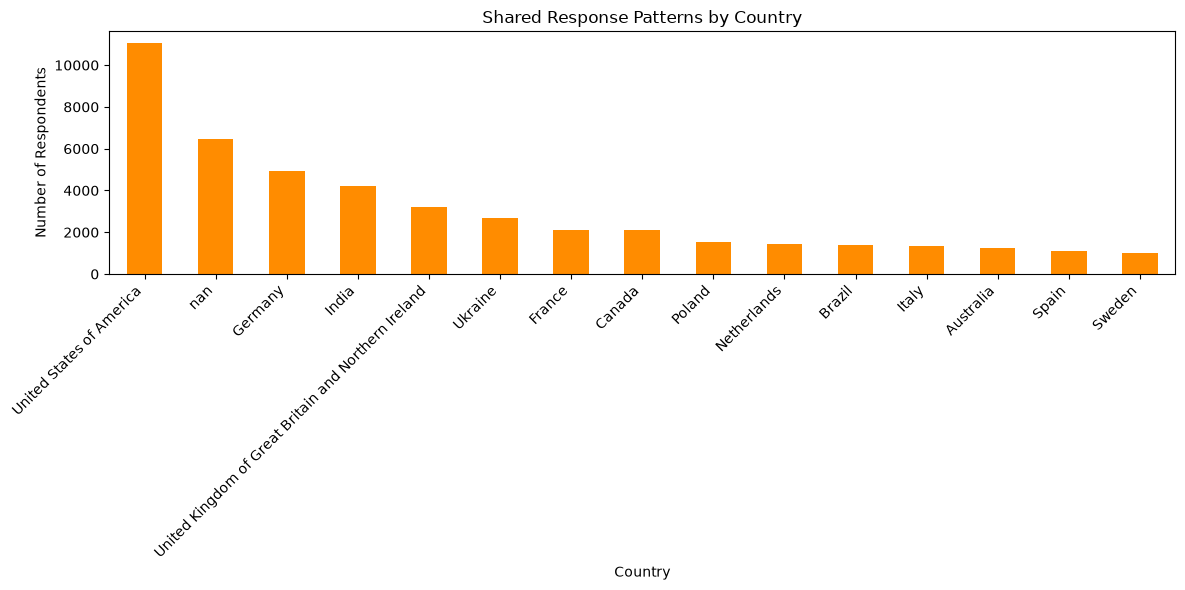

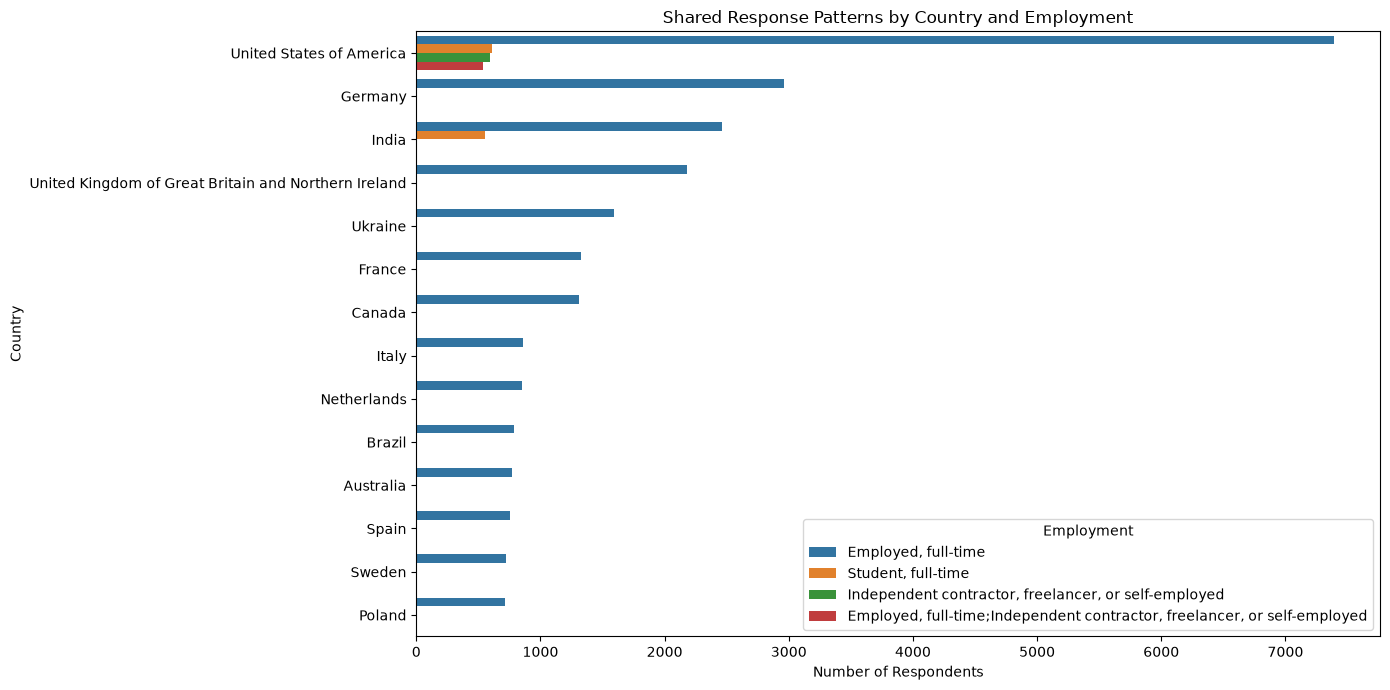

In [7]:
## Write your code here
!pip install seaborn
import matplotlib.pyplot as plt
import seaborn as sns
pattern_columns = ["MainBranch", "Employment", "RemoteWork"]

df["ResponsePattern"] = ( df[pattern_columns].fillna("Missing").astype(str).agg(" | ".join, axis=1))


pattern_counts = df["ResponsePattern"].value_counts()

# Pattern condivisi da almeno due rispondenti
shared_patterns = pattern_counts[pattern_counts > 1].index
# Un pattern presente una sola volta non è condiviso. Un pattern presente almeno due volte è condiviso da più rispondenti.

df["SharedPattern"] = df["ResponsePattern"].isin(shared_patterns)
# abbiamo creato una nuova colonna "SharedPattern" che indica se il pattern di risposta di ciascun rispondente è condiviso da almeno un altro rispondente. 
# Se il pattern è condiviso, il valore sarà True; altrimenti, sarà False.

#Creazione di un grafico a barre per visualizzare la distribuzione dei rispondenti che condividono i pattern di MainBranch, Employment e RemoteWork.
employment_distribution = (
    df[df["SharedPattern"]]
    .groupby("Employment", dropna=False)
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

employment_distribution.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Respondents Sharing MainBranch, Employment and RemoteWork Patterns")
plt.xlabel("Employment")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
#************************

#Creazione di un grafico a barre per visualizzare la distribuzione dei rispondenti che condividono i pattern di MainBranch, Employment e RemoteWork per Paese.
country_distribution = (
    df[df["SharedPattern"]]
    .groupby("Country", dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(15)
)
plt.figure(figsize=(12, 6))

country_distribution.plot(
    kind="bar",
    color="darkorange"
)

plt.title("Shared Response Patterns by Country")
plt.xlabel("Country")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
#************************
#Creazione di un grafico a barre per visualizzare la distribuzione dei rispondenti che condividono i pattern di MainBranch, Employment e RemoteWork per Paese e tipo di impiego.
country_employment_distribution = (
    df[df["SharedPattern"]]
    .groupby(["Country", "Employment"], dropna=False)
    .size()
    .reset_index(name="RespondentCount")
    .sort_values("RespondentCount", ascending=False)
)

top_combinations = country_employment_distribution.head(20)
plt.figure(figsize=(14, 7))
sns.barplot(
    data=top_combinations,
    x="RespondentCount",
    y="Country",
    hue="Employment"
)

plt.title("Shared Response Patterns by Country and Employment")
plt.xlabel("Number of Respondents")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
#******************************


### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


## Verify and Document Duplicate Removal Process


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
